In [ ]:
!pip install -U segmentation-models-pytorch

In [ ]:
import os
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from google.colab import drive

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

SEED = 42
BATCH_SIZE = 16
EPOCHS = 20
LR = 1e-4
NUM_WORKERS = 2

ENCODER_NAME = "resnet34"

drive.mount('/content/drive')
ARCHIVE_PATH = Path('/content/drive/MyDrive/datasets/Satellite Images of Water Bodies.zip')
EXTRACT_DIR = Path('data/satellite_water')

Mounted at /content/drive


In [ ]:
def prepare_dataset(archive_path: Path, extract_dir: Path) -> Path:
    if not archive_path.exists():
        raise FileNotFoundError(f'Не найден архив: {archive_path.resolve()}')
    if not zipfile.is_zipfile(archive_path):
        raise RuntimeError('Архив пока невалидный как zip. Дождись окончания загрузки файла.')

    if not extract_dir.exists():
        extract_dir.mkdir(parents=True, exist_ok=True)
        print("Распаковка датасета... Пожалуйста, подождите.")
        with zipfile.ZipFile(archive_path, 'r') as zf:
            zf.extractall(extract_dir)
        print("Распаковка успешно завершена!")
    return extract_dir
dataset_root = prepare_dataset(ARCHIVE_PATH, EXTRACT_DIR)

Распаковка датасета... Пожалуйста, подождите.
Распаковка успешно завершена!


In [ ]:
def verify_dataset_structure(dataset_path: Path):
    images_candidates = list(dataset_path.rglob('Images'))
    masks_candidates = list(dataset_path.rglob('Masks'))

    if not images_candidates or not masks_candidates:
        raise RuntimeError("Не удалось найти папки 'Images' или 'Masks'!")

    images_dir = images_candidates[0]
    masks_dir = masks_candidates[0]

    img_files = sorted(list(images_dir.glob('*.*')))
    mask_files = sorted(list(masks_dir.glob('*.*')))

    print(f"Найдено изображений: {len(img_files)}")
    print(f"Найдено масок:      {len(mask_files)}")

    return images_dir, masks_dir
images_path, masks_path = verify_dataset_structure(dataset_root)

Найдено изображений: 2841
Найдено масок:      2841


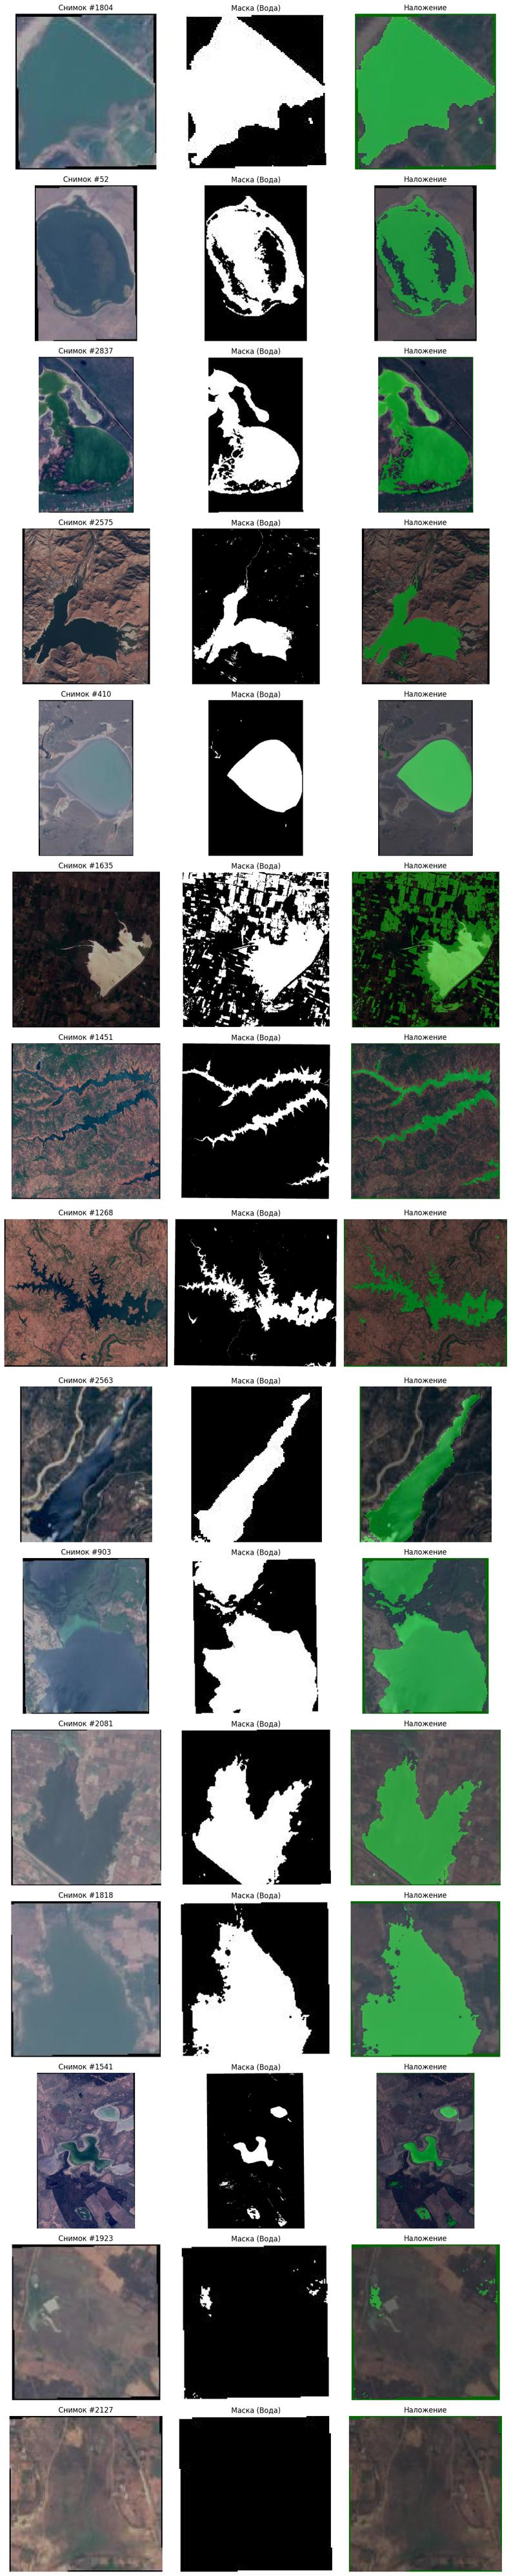

In [ ]:
class SatelliteWaterDataset(Dataset):
    def __init__(self, images_dir: Path, masks_dir: Path):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.image_names = sorted(os.listdir(images_dir))
        self.mask_names = sorted(os.listdir(masks_dir))

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, idx):
        img_path = os.path.join(self.images_dir, self.image_names[idx])
        mask_path = os.path.join(self.masks_dir, self.mask_names[idx])
        image = torch.from_numpy(np.array(Image.open(img_path).convert("RGB"))).permute(2, 0, 1).float() / 255.0
        mask = torch.from_numpy(np.array(Image.open(mask_path).convert("L"))).float().unsqueeze(0) / 255.0
        return image, mask

def show_segmentation_examples(dataset, n=3, seed=42):
    random.seed()
    indices = random.sample(range(len(dataset)), n)
    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))

    for i, idx in enumerate(indices):
        image_tensor, mask_tensor = dataset[idx]
        image = image_tensor.permute(1, 2, 0).numpy()
        mask = mask_tensor.squeeze(0).numpy()

        axes[i, 0].imshow(image)
        axes[i, 0].set_title(f"Снимок #{idx}")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title("Маска (Вода)")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(image)
        mask_overlay = np.zeros_like(image)
        mask_overlay[mask > 0.5] = [0, 1, 0]
        axes[i, 2].imshow(mask_overlay, alpha=0.4)
        axes[i, 2].set_title("Наложение")
        axes[i, 2].axis("off")
    plt.tight_layout()
    plt.show()
raw_dataset = SatelliteWaterDataset(images_path, masks_path)
show_segmentation_examples(raw_dataset, n=15)

In [ ]:
class SatelliteWaterDatasetSMP(Dataset):
    """Кастомный класс Dataset для корректной работы с albumentations и SMP."""
    def __init__(self, images_dir: Path, masks_dir: Path, filenames: list, transform=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.filenames = filenames
        self.transform = transform

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]
        img_path = os.path.join(self.images_dir, filename)
        mask_path = os.path.join(self.masks_dir, filename)

        image = np.array(Image.open(img_path).convert("RGB"))
        mask = np.array(Image.open(mask_path).convert("L"))

        mask = (mask > 0).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        if isinstance(mask, torch.Tensor):
            mask = mask.unsqueeze(0)
        else:
            mask = torch.from_numpy(np.expand_dims(mask, axis=0)).float()

        return image, mask

In [ ]:
def build_pipeline(images_dir: Path, masks_dir: Path, batch_size: int = 16):
    """Управляющая функция: настраивает аугментации, делит данные и возвращает DataLoader-ы."""

    train_transform = A.Compose([
        A.Resize(256, 256),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

    valid_transform = A.Compose([
        A.Resize(256, 256),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

    all_filenames = sorted(os.listdir(images_dir))
    random.seed(42)
    random.shuffle(all_filenames)

    split_idx = int(len(all_filenames) * 0.8)
    train_files = all_filenames[:split_idx]
    valid_files = all_filenames[split_idx:]

    train_dataset = SatelliteWaterDatasetSMP(images_dir, masks_dir, train_files, transform=train_transform)
    valid_dataset = SatelliteWaterDatasetSMP(images_dir, masks_dir, valid_files, transform=valid_transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, drop_last=True)
    valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    print(f"Обучающая выборка:   {len(train_dataset)} картинок ({len(train_loader)} батчей)")
    print(f"Валидационная выборка: {len(valid_dataset)} картинок ({len(valid_loader)} батчей)")

    return train_loader, valid_loader
train_loader, valid_loader = build_pipeline(images_path, masks_path, batch_size=BATCH_SIZE)

Обучающая выборка:   2272 картинок (142 батчей)
Валидационная выборка: 569 картинок (36 батчей)


In [ ]:
def initialize_unet_model(encoder_name: str = "resnet34", encoder_weights: str = "imagenet") -> nn.Module:
    """Создает модель Unet из библиотеки SMP с заданным энкодером."""
    model = smp.Unet(
        encoder_name=encoder_name,
        encoder_weights=encoder_weights,
        in_channels=3,
        classes=1,
    )
    model.to("cuda")
    return model
segmentation_model = initialize_unet_model(encoder_name=ENCODER_NAME, encoder_weights="imagenet")

In [ ]:
def configure_loss_and_optimizer(model_pipeline: nn.Module, learning_rate: float = 1e-4):
    """Настраивает функцию потерь (Dice + BCE) и оптимизатор Adam."""

    smp_dice_loss = smp.losses.DiceLoss(mode='binary')
    torch_bce_loss = nn.BCEWithLogitsLoss()

    def combined_criterion(y_pred, y_true):
        return smp_dice_loss(y_pred, y_true) + torch_bce_loss(y_pred, y_true)

    adam_optimizer = optim.Adam(model_pipeline.parameters(), lr=learning_rate)

    print(f"Функция потерь: CombinedLoss (DiceLoss [smp] + BCEWithLogitsLoss)")
    print(f"Оптимизатор:   Adam (learning rate: {learning_rate})")

    return combined_criterion, adam_optimizer
criterion, optimizer = configure_loss_and_optimizer(segmentation_model, learning_rate=LR)

Функция потерь: CombinedLoss (DiceLoss [smp] + BCEWithLogitsLoss)
Оптимизатор:   Adam (learning rate: 0.0001)


In [ ]:
def calculate_segmentation_metrics(y_pred: torch.Tensor, y_true: torch.Tensor, eps: float = 1e-7):
    """Вычисляет метрики IoU, Dice и Pixel Accuracy для бинарной сегментации."""
    preds = (torch.sigmoid(y_pred) > 0.5).float()
    targets = y_true.float()

    preds_flat = preds.view(-1)
    targets_flat = targets.view(-1)

    intersection = (preds_flat * targets_flat).sum().item()
    sum_pixels = preds_flat.sum().item() + targets_flat.sum().item()
    union = sum_pixels - intersection

    iou = (intersection + eps) / (union + eps)
    dice = (2.0 * intersection + eps) / (sum_pixels + eps)

    correct_pixels = (preds_flat == targets_flat).sum().item()
    pixel_accuracy = correct_pixels / targets_flat.numel()

    return iou, dice, pixel_accuracy

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    """Проводит одну эпоху обучения модели."""
    model.train()
    running_loss, running_iou, running_dice, running_acc = 0.0, 0.0, 0.0, 0.0

    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        iou, dice, acc = calculate_segmentation_metrics(outputs, masks)
        running_iou += iou
        running_dice += dice
        running_acc += acc

    num_batches = len(loader)
    return (running_loss / num_batches, running_iou / num_batches,
            running_dice / num_batches, running_acc / num_batches)

In [ ]:
def validate_one_epoch(model, loader, criterion, device):
    """Проводит одну эпоху валидации модели."""
    model.eval()
    running_loss, running_iou, running_dice, running_acc = 0.0, 0.0, 0.0, 0.0

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            outputs = model(images)
            loss = criterion(outputs, masks)

            running_loss += loss.item()
            iou, dice, acc = calculate_segmentation_metrics(outputs, masks)
            running_iou += iou
            running_dice += dice
            running_acc += acc

    num_batches = len(loader)
    return (running_loss / num_batches, running_iou / num_batches,
            running_dice / num_batches, running_acc / num_batches)

In [ ]:
def run_high_precision_training(model_pipeline: nn.Module, train_data_loader: DataLoader, valid_data_loader: DataLoader):
    loss_criterion, adam_optimizer = configure_loss_and_optimizer(model_pipeline, learning_rate=LR)
    lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        adam_optimizer,
        mode='min',
        patience=2,
        factor=0.5
    )

    best_valid_iou = 0.0
    print(f"Параметры эксперимента: Эпох: {EPOCHS} | Наша стартовая LR: {LR} | Batch Size: {BATCH_SIZE}\n")

    for epoch in range(EPOCHS):
        train_loss, train_iou, train_dice, train_acc = train_one_epoch(
            model_pipeline, train_data_loader, loss_criterion, adam_optimizer, "cuda"
        )
        valid_loss, valid_iou, valid_dice, valid_acc = validate_one_epoch(
            model_pipeline, valid_data_loader, loss_criterion, "cuda"
        )
        lr_scheduler.step(valid_loss)

        print(f"Эпоха [{epoch+1}/{EPOCHS}]")
        print(f"   [Train] Loss: {train_loss:.4f} | IoU: {train_iou:.4f} | Dice: {train_dice:.4f} | Accuracy: {train_acc:.4f}")
        print(f"   [Valid] Loss: {valid_loss:.4f} | IoU: {valid_iou:.4f} | Dice: {valid_dice:.4f} | Accuracy: {valid_acc:.4f}")

        if valid_iou > best_valid_iou:
            best_valid_iou = valid_iou
            torch.save(model_pipeline.state_dict(), 'best_water_unet.pth')
            print(f"--> Высший IoU на валидации: {best_valid_iou:.4f}")

    print(f"\nОбучение завершено! Лучший зафиксированный IoU: {best_valid_iou:.4f}")
    return model_pipeline

segmentation_model = run_high_precision_training(segmentation_model, train_loader, valid_loader)

Функция потерь: CombinedLoss (DiceLoss [smp] + BCEWithLogitsLoss)
Оптимизатор:   Adam (learning rate: 0.0001)
Параметры эксперимента: Эпох: 20 | Наша стартовая LR: 0.0001 | Batch Size: 16

Эпоха [1/20]
   [Train] Loss: 0.8517 | IoU: 0.5742 | Dice: 0.7192 | Accuracy: 0.7928
   [Valid] Loss: 0.6563 | IoU: 0.6590 | Dice: 0.7926 | Accuracy: 0.8519
--> Высший IoU на валидации: 0.6590
Эпоха [2/20]
   [Train] Loss: 0.6221 | IoU: 0.6772 | Dice: 0.8060 | Accuracy: 0.8551
   [Valid] Loss: 0.5869 | IoU: 0.6843 | Dice: 0.8109 | Accuracy: 0.8646
--> Высший IoU на валидации: 0.6843
Эпоха [3/20]
   [Train] Loss: 0.5645 | IoU: 0.6984 | Dice: 0.8208 | Accuracy: 0.8667
   [Valid] Loss: 0.5520 | IoU: 0.6979 | Dice: 0.8199 | Accuracy: 0.8710
--> Высший IoU на валидации: 0.6979
Эпоха [4/20]
   [Train] Loss: 0.5305 | IoU: 0.7143 | Dice: 0.8322 | Accuracy: 0.8753
   [Valid] Loss: 0.5497 | IoU: 0.6934 | Dice: 0.8166 | Accuracy: 0.8664
Эпоха [5/20]
   [Train] Loss: 0.5187 | IoU: 0.7163 | Dice: 0.8333 | Accurac

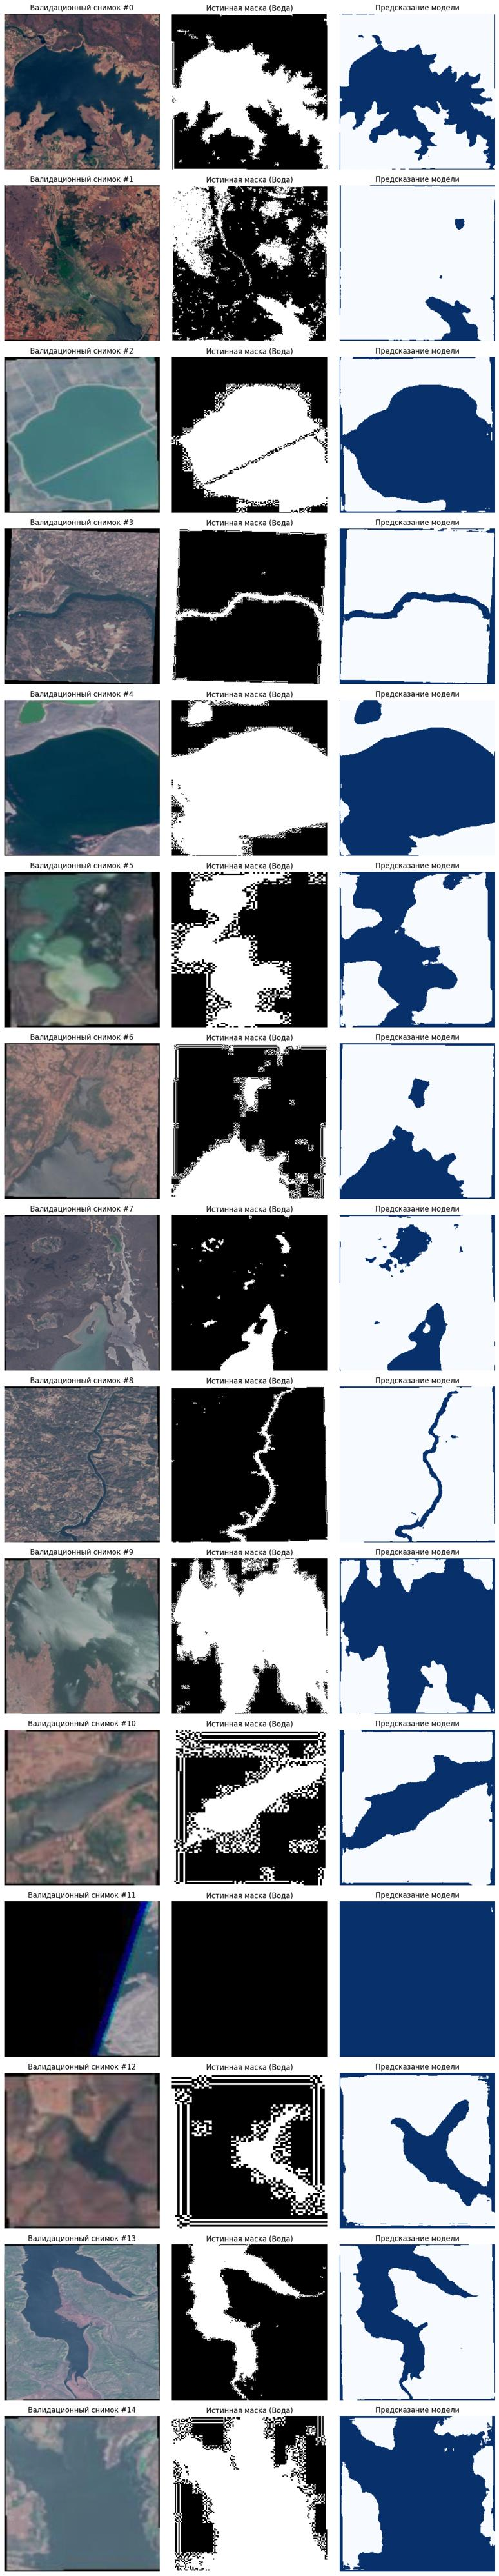

In [ ]:
def visualize_predictions(model: nn.Module, loader: DataLoader, n_samples: int = 3):
    """Выбирает случайные снимки из валидационного лоадера и сравнивает истинную маску с предсказанием модели."""
    model.eval()
    images, masks = next(iter(loader))

    with torch.no_grad():
        outputs = model(images.to("cuda"))
        preds = (torch.sigmoid(outputs) > 0.5).float().cpu()

    fig, axes = plt.subplots(n_samples, 3, figsize=(12, 4 * n_samples))

    for i in range(min(n_samples, len(images))):
        img = images[i].permute(1, 2, 0).numpy()
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img = np.clip(img, 0, 1)

        true_mask = masks[i].squeeze(0).numpy()
        pred_mask = preds[i].squeeze(0).numpy()

        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Валидационный снимок #{i}")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(true_mask, cmap="gray")
        axes[i, 1].set_title("Истинная маска (Вода)")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pred_mask, cmap="Blues")
        axes[i, 2].set_title("Предсказание модели")
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions(segmentation_model, valid_loader, n_samples=15)